# step0 sanity: does the NFP solve reproduce its own data?

`code.npy` and `prb.npy` come out of step0's near-field ptychography. The sharpest test of that
solve is whether it reproduces the frames it was actually fitted to:

    pdata[k]  ==  | D_nfp( prb * code_window(pos[k]) ) |^2

one propagation at the CODE-plane geometry (voxelsize 42.12 nm, distance -18.00 mm), not the
two-step code->sample->detector chain the holotomography side uses.

Frames are picked to span **different regions of the aperture**, because that is the thing in
question. With 324 positions, a 2048 px window and an 8192 px plane, the centre of the code is
seen by nearly every position and the rim by very few -- so the code can be well reconstructed in
the middle and unreliable at the edges, and a single frame cannot tell you which.

**Positions matter and step0 currently discards them.** It saves only `code.npy` and `prb.npy`;
`cl.vars['pos']` is thrown away after the solve. `data_nfp.h5`'s `shifts` are step0b's *starting*
estimates, which the solver moves several px away from. Scoring at those stale shifts scores the
model at positions the solver already rejected. This notebook uses `pos_nfp.npy` when present and
warns loudly when it is not -- to produce it, add one line next to the saves in `step0.py`:

    np.save(os.path.join(os.path.dirname(args.code_out), 'pos_nfp.npy'),
            cp.asnumpy(cl.vars['pos']))

In [1]:
# Paths (hardcoded: this notebook does not read config_step0.conf)
PATH_NFP  = '/data3/cekmekci/AtomiumS2_coded/nfp/data_nfp.h5'
PATH_CODE = '/data3/cekmekci/AtomiumS2_coded/nfp/code.npy'
PATH_PRB  = '/data3/cekmekci/AtomiumS2_coded/nfp/prb.npy'
PATH_POS  = '/data3/cekmekci/AtomiumS2_coded/nfp/pos_nfp.npy'   # step0's refined positions, if saved

N_SHOW = 9        # frames to inspect, spread over the aperture
CROP   = 128      # px ignored at every edge; the modelled rim is unreliable

In [2]:
import os
import numpy as np
import cupy as cp
import h5py
import matplotlib.pyplot as plt
%matplotlib inline
from holotomocupy.propagation import Propagation

with h5py.File(PATH_NFP, 'r') as f:
    energy  = float(f['/exchange/energy'][0])
    fdd     = float(f['/exchange/focusdetectordistance'][0])
    z1      = float(f['/exchange/z1'][0])
    vox     = float(f['/exchange/voxelsize'][0])
    shifts  = f['/exchange/shifts'][:].astype('float32')
    npos, nz, n = f['/exchange/pdata'].shape

wavelength = 1.24e-9 / energy
distance   = z1 * (fdd - z1) / fdd            # NEGATIVE: aperture upstream of the focus

code_gpu = cp.asarray(np.load(PATH_CODE).astype('complex64'))
prb_gpu  = cp.asarray(np.load(PATH_PRB).astype('complex64'))
ncode = code_gpu.shape[0]
Dnfp = Propagation(n, nz, 1, 1, wavelength, vox, [distance])

# step0.py's own centring of the scan positions
pos = shifts.copy()
pos[:, 0] -= (pos[:, 0].max() + pos[:, 0].min()) / 2
pos[:, 1] -= (pos[:, 1].max() + pos[:, 1].min()) / 2
pos_start = pos.copy()          # what RecNFPCoded rounded to freeze its gather offsets

USING_REFINED = os.path.exists(PATH_POS)
if USING_REFINED:
    refined = np.load(PATH_POS).astype('float32')
    if refined.shape == pos.shape:
        moved = np.abs(refined - pos)
        print(f'using step0 REFINED positions from {PATH_POS}')
        print(f'  they differ from step0b\'s by mean |dy| {moved[:,0].mean():.3f} px, '
              f'mean |dx| {moved[:,1].mean():.3f} px')
        pos = refined
    else:
        print(f'WARNING: {PATH_POS} has shape {refined.shape}, expected {pos.shape} -- ignoring')
        USING_REFINED = False
if not USING_REFINED:
    print('=' * 78)
    print('WARNING: no pos_nfp.npy. Falling back to step0b\'s STARTING shifts.')
    print('step0 refines the positions and discards them, so the model is being scored at')
    print('positions the solver moved away from. Expect this to understate the fit quality;')
    print('a poor result below is NOT conclusive until step0 saves its positions.')
    print('=' * 78)

# RecNFPCoded froze off = round(STARTING positions) once in precalc and never re-rounded --
# deliberately, so that a position crossing a half-integer cannot make the objective jump. The
# consequence is that the FFT carried the WHOLE remaining drift, not a subpixel remainder, and
# the model below has to split the shift the same way to be the model that was actually fitted.
pos_off = np.round(pos_start).astype('int32')
_res = np.abs(pos - pos_off)
print(f'  residual left for the FFT: mean {_res.mean():.3f} px, max {_res.max():.3f} px; '
      f'{int((np.round(pos_start) != np.round(pos)).any(1).sum())}/{npos} positions crossed a '
      f'rounding boundary during the solve')

print()
print(f'{npos} positions, detector {nz}x{n}, code {ncode}^2')
print(f'distance {distance*1e3:.4f} mm   voxelsize {vox*1e9:.3f} nm   '
      f'shift span row [{pos[:,0].min():.0f},{pos[:,0].max():.0f}] '
      f'col [{pos[:,1].min():.0f},{pos[:,1].max():.0f}] px')

using step0 REFINED positions from /data3/cekmekci/AtomiumS2_coded/nfp/pos_nfp.npy
  they differ from step0b's by mean |dy| 3.791 px, mean |dx| 0.681 px

324 positions, detector 2048x2048, code 8192^2
distance -17.9961 mm   voxelsize 42.122 nm   shift span row [-2445,2446] col [-2609,2608] px


/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/propagation.py:44: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  self._use_cufftdx = cufftdx_available()


## Coverage: which parts of the aperture are actually constrained?

Each position sees a 2048 px window of the 8192 px plane, centred at `ncode/2 - pos`. Counting how
many windows cover each pixel shows directly where the code is over-determined and where it rests
on a handful of frames. The frames inspected below are chosen to span this map rather than cluster
in the well-covered middle.

selected frames: [0, 8, 17, 144, 161, 171, 306, 315, 323]


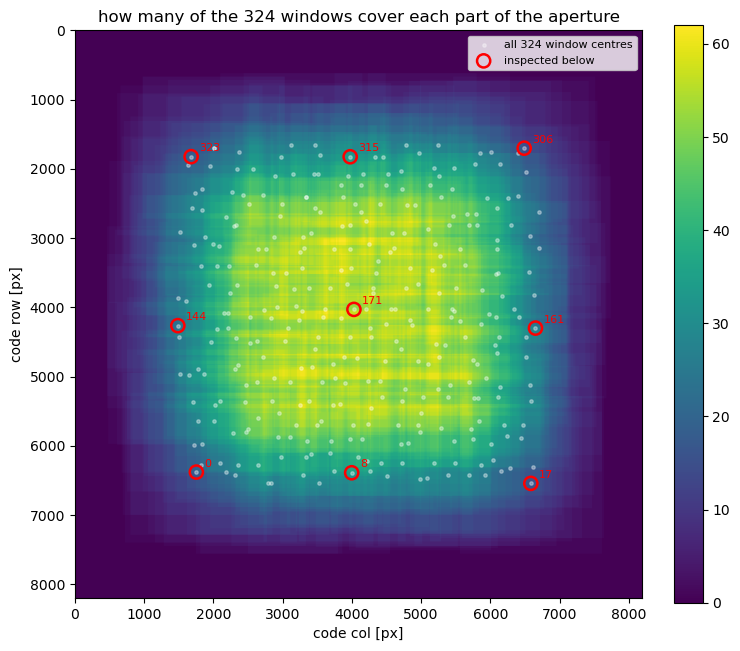

coverage: max 62 windows, min 0, 27.2% of the plane seen by none


In [3]:
DS = 16                                    # downsample factor for the coverage map
m = ncode // DS
cov = np.zeros((m, m), dtype='int32')
half = n // 2
for k in range(npos):
    r0 = int(round(ncode // 2 - pos[k, 0])) - half
    c0 = int(round(ncode // 2 - pos[k, 1])) - half
    cov[max(0, r0)//DS:(r0+n)//DS, max(0, c0)//DS:(c0+n)//DS] += 1

# pick N_SHOW frames spanning the covered area: nearest to a 3x3 grid of targets
ctr = np.stack([ncode/2 - pos[:, 0], ncode/2 - pos[:, 1]], axis=1)   # window centre of each frame
lo, hi = ctr.min(0), ctr.max(0)
targets = [(lo[0] + (hi[0]-lo[0])*a, lo[1] + (hi[1]-lo[1])*b)
           for a in (0.0, 0.5, 1.0) for b in (0.0, 0.5, 1.0)][:N_SHOW]
sel, used = [], set()
for t in targets:
    d = np.hypot(ctr[:, 0]-t[0], ctr[:, 1]-t[1])
    for k in np.argsort(d):
        if k not in used:
            sel.append(int(k)); used.add(int(k)); break
sel = sorted(sel)
print('selected frames:', sel)

fig, ax = plt.subplots(figsize=(7.5, 7))
im = ax.imshow(cov, cmap='viridis', extent=(0, ncode, ncode, 0))
ax.scatter(ctr[:, 1], ctr[:, 0], s=6, c='white', alpha=0.35, label='all 324 window centres')
ax.scatter(ctr[sel, 1], ctr[sel, 0], s=90, facecolors='none', edgecolors='red',
           linewidths=1.8, label='inspected below')
for k in sel:
    ax.annotate(str(k), (ctr[k, 1], ctr[k, 0]), color='red', fontsize=8,
                xytext=(6, 4), textcoords='offset points')
ax.set(title='how many of the 324 windows cover each part of the aperture',
       xlabel='code col [px]', ylabel='code row [px]')
ax.legend(fontsize=8, loc='upper right'); fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()
print(f'coverage: max {cov.max()} windows, min {cov.min()}, '
      f'{100*(cov==0).mean():.1f}% of the plane seen by none')

## Fit, frame by frame

Measurement, model, their plain **difference**, and their **ratio** -- no normalisation. `pdata`
is flat-normalised by step0b and the model is built from the same quantities step0 fitted, so both
should already sit on the same scale; the two mean columns in the table say whether they do. If
they disagree, that is itself a result and should not be hidden by rescaling.

Measurement and model share one grey scale so a brightness mismatch is visible rather than
normalised away. The difference is symmetric about zero, clipped at the 99th percentile of
|difference|. The ratio is centred on 1, clipped at the 99th percentile of |ratio - 1|. The actual
images are in the next cell (`montage`); this one only prints the summary table.

In [4]:
c_ = (slice(CROP, nz - CROP), slice(CROP, n - CROP))

# THE MODEL MUST USE THE SHIFTER THE SOLVER USED. RecNFPCoded gathers an
# [nz + 2*pad, n + 2*pad] window out of the code plane, tapers the pad with a raised cosine and
# FFT-shifts inside it, with pad = window_pad(n, nz, pos_pad_frac) = 256 here. This cell used to
# re-split the shift at the FINAL position into an 8 px untapered crop, which is a different
# operator: shift_fft_code measures ~1/sqrt(pad) rms error off the window edge, 9.2e-4 untapered
# at pad=16, against a solve whose own data error is 4.7e-4. The mismatch would show up in
# `measured - model` and read as physics.
from holotomocupy.shift_fft_code import ShiftFFTCode, window_pad

POS_PAD_FRAC = 0.125                                  # config_step0.conf
pad_y, pad_x = window_pad(n, nz, POS_PAD_FRAC)
cl_shift = ShiftFFTCode(n, n + 2 * pad_x, nz, nz + 2 * pad_y, nchunk=1,
                        pad=(pad_y, pad_x), code_shape=(ncode, ncode))
_m1 = cl_shift.unit_mag(1)
print(f'window {nz + 2 * pad_y} x {n + 2 * pad_x} (pad {pad_y}, {pad_x}) out of {ncode}^2, '
      f'pos_pad_frac={POS_PAD_FRAC:g}')


def model_at(k):
    """Model at pos[k], through RecNFPCoded's own windowed shifter.

    The integer part rides in the frozen gather offset pos_off[k], exactly as in the solve, and
    only pos[k] - pos_off[k] goes through the FFT. check_drift raises if that residual has grown
    past what the pad can absorb, i.e. if this is not the window the solver used.
    """
    r = cp.asarray(pos[k:k + 1], dtype='float32')
    o = cp.asarray(pos_off[k:k + 1], dtype='int32')
    cl_shift.check_drift(r, o)
    w = cl_shift.S(code_gpu, r, _m1, o)[0]
    return cp.abs(Dnfp.D(prb_gpu * w, 0)) ** 2


rows = []
store = {}
with h5py.File(PATH_NFP, 'r') as f:
    for k in sel:
        meas = cp.asarray(f['/exchange/pdata'][k].astype('float32'))
        mod = model_at(k)
        dif = meas - mod                                    # plain difference, no normalisation
        rms = float(cp.sqrt((dif[c_] ** 2).mean()))
        cy, cx_ = ctr[k]
        covk = int(cov[min(m - 1, int(cy) // DS), min(m - 1, int(cx_) // DS)])
        rows.append((k, pos[k, 0], pos[k, 1], np.hypot(pos[k, 0], pos[k, 1]), covk,
                     rms, float(meas[c_].mean()), float(mod[c_].mean())))
        store[k] = (cp.asnumpy(meas), cp.asnumpy(mod), cp.asnumpy(dif))
        del meas, mod, dif
cp.get_default_memory_pool().free_all_blocks()

print(f'{"frame":>6} {"pos (row,col)":>20} {"|pos|":>8} {"cover":>6} '
      f'{"RMS(meas-model)":>16} {"mean meas":>10} {"mean model":>11}')
for k, py, px, pr, covk, rms, mm, md_ in rows:
    print(f'{k:6d} ({py:+8.1f},{px:+8.1f}) {pr:8.0f} {covk:6d} {rms:16.4f} {mm:10.4f} {md_:11.4f}')
arr = np.array([(r[3], r[4], r[5]) for r in rows])
print()
print(f'RMS: min {arr[:,2].min():.4f}  median {np.median(arr[:,2]):.4f}  max {arr[:,2].max():.4f}')
print('absolute units -- pdata is flat-normalised so both sit near 1; compare the two mean columns')
print('to see whether model and measurement are even on the same scale.')
if not USING_REFINED:
    print('(remember: stale positions -- see the warning in the setup cell)')

 frame        pos (row,col)    |pos|  cover  RMS(meas-model)  mean meas  mean model
     0 ( -2282.6, +2340.9)     3270     19           0.0360     1.0672      1.0555
     8 ( -2292.2,   +98.8)     2294     35           0.0331     1.0614      1.0552
    17 ( -2445.4, -2487.3)     3488     16           0.0368     1.0562      1.0549
   144 (  -168.3, +2608.4)     2614     23           0.0425     1.0383      1.0386
   161 (  -204.0, -2554.6)     2563     27           0.0342     1.0358      1.0364
   171 (   +66.0,   +66.4)       94     52           0.0309     1.0371      1.0364
   306 ( +2393.2, -2391.5)     3383     15           0.0375     1.0282      1.0275
   315 ( +2269.7,  +120.5)     2273     34           0.0340     1.0286      1.0257
   323 ( +2271.3, +2416.4)     3316     18           0.0352     1.0268      1.0259

RMS: min 0.0309  median 0.0352  max 0.0425
absolute units -- pdata is flat-normalised so both sit near 1; compare the two mean columns
to see whether model and measurem

In [ ]:
nrow = len(sel)
fig, ax = plt.subplots(nrow, 4, figsize=(18.5, 4.4 * nrow))
for i, k in enumerate(sel):
    meas, mod, dif = store[k]
    lo_, hi_ = np.percentile(meas[c_], [1, 99])          # one scale for measurement AND model
    v = np.percentile(np.abs(dif[c_]), 99)
    rat = meas / np.maximum(mod, 1e-3)
    rv = np.percentile(np.abs(rat[c_] - 1), 99)
    for j, (img, t, kw) in enumerate((
            (meas, f'frame {k}: measured', dict(cmap='gray', vmin=lo_, vmax=hi_)),
            (mod, 'model', dict(cmap='gray', vmin=lo_, vmax=hi_)),
            (dif, 'measured - model', dict(cmap='seismic', vmin=-v, vmax=v)),
            (rat, 'measured / model', dict(cmap='seismic', vmin=1 - rv, vmax=1 + rv)))):
        a = ax[i, j] if nrow > 1 else ax[j]
        im = a.imshow(img, **kw)
        a.set_title(f'{t}' + (f'   pos ({pos[k,0]:+.0f},{pos[k,1]:+.0f})' if j == 0 else ''),
                    fontsize=9)
        a.set_xticks([]); a.set_yticks([])
        fig.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## Is the fit worse where the aperture is less covered?

If the code is reconstructed reliably everywhere, RMS of the difference should be flat across
positions. If it degrades with distance from the centre -- equivalently, with falling coverage --
the solve is fine where the data constrains it and unreliable at the rim, and only the central
region of `code.npy` should be trusted.

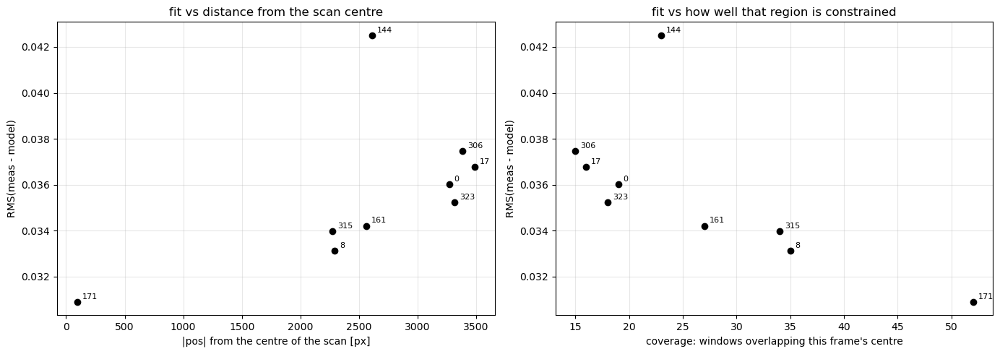

corr(RMS, distance from centre) = +0.571   (positive => worse further out)
corr(RMS, coverage)             = -0.670   (negative => worse where fewer windows overlap)


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(arr[:, 0], arr[:, 2], 'ko')
for (k, py, px, pr, covk, rms, mm, md_) in rows:
    ax[0].annotate(str(k), (pr, rms), fontsize=8, xytext=(5, 3), textcoords='offset points')
ax[0].set(xlabel='|pos| from the centre of the scan [px]', ylabel='RMS(meas - model)',
          title='fit vs distance from the scan centre')
ax[0].grid(alpha=0.3)

ax[1].plot(arr[:, 1], arr[:, 2], 'ko')
for (k, py, px, pr, covk, rms, mm, md_) in rows:
    ax[1].annotate(str(k), (covk, rms), fontsize=8, xytext=(5, 3), textcoords='offset points')
ax[1].set(xlabel="coverage: windows overlapping this frame's centre", ylabel='RMS(meas - model)',
          title='fit vs how well that region is constrained')
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

if len(arr) > 2:
    cr_ = np.corrcoef(arr[:, 0], arr[:, 2])[0, 1]
    cv_ = np.corrcoef(arr[:, 1], arr[:, 2])[0, 1]
    print(f'corr(RMS, distance from centre) = {cr_:+.3f}   (positive => worse further out)')
    print(f'corr(RMS, coverage)             = {cv_:+.3f}   (negative => worse where fewer windows overlap)')

## PSF sweep: look at the frames

For one frame, measured / blurred model / difference at each PSF sigma. The forward model has no
detector blur (`psf_sigma=0.0`), so if the detector is blurring intensity, the right sigma should
visibly flatten the difference panel.

Uses the package's own `psf_taps`, which builds the DISCRETE Gaussian `exp(-s^2) I_|t|(s^2)` --
a sampled Gaussian aliases below ~0.7 px (sigma 0.3 realises as 0.09), so `gaussian_filter` is the
wrong tool for exactly this test.

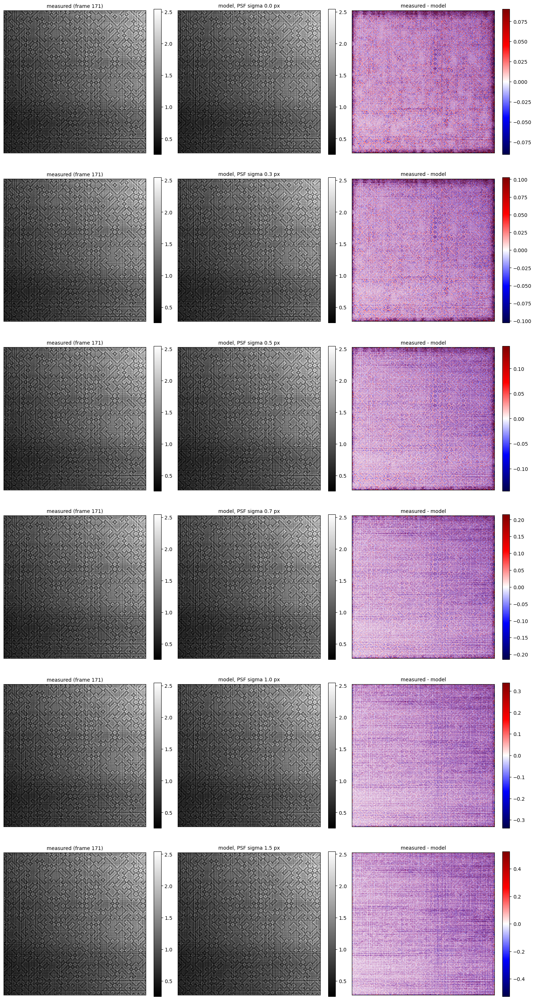

In [7]:
from holotomocupy.psf import psf_taps, psf_blur

PSF_FRAME  = 171                                      # which frame to look at
PSF_SIGMAS = [0.0, 0.3, 0.5, 0.7, 1.0, 1.5]

meas, mod, _ = store[PSF_FRAME]
mg, dg = cp.asarray(meas), cp.asarray(mod)

nrow = len(PSF_SIGMAS)
fig, ax = plt.subplots(nrow, 3, figsize=(15, 4.7 * nrow))
lo, hi = np.percentile(meas[c_], [1, 99])
for i, s in enumerate(PSF_SIGMAS):
    w = psf_taps(s)[1]
    m2 = dg if w is None else psf_blur(dg, w)
    dif = cp.asnumpy(mg - m2)
    m2n = cp.asnumpy(m2)
    v = np.percentile(np.abs(dif[c_]), 99)
    for j, (img, t, kw) in enumerate((
            (meas, f'measured (frame {PSF_FRAME})', dict(cmap='gray', vmin=lo, vmax=hi)),
            (m2n,  f'model, PSF sigma {s:.1f} px', dict(cmap='gray', vmin=lo, vmax=hi)),
            (dif,  'measured - model', dict(cmap='seismic', vmin=-v, vmax=v)))):
        a = ax[i, j]
        im = a.imshow(img, **kw)
        a.set_title(t, fontsize=10)
        a.set_xticks([]); a.set_yticks([])
        fig.colorbar(im, ax=a, fraction=0.046)
del mg, dg
cp.get_default_memory_pool().free_all_blocks()
plt.tight_layout(); plt.show()

## Look at the product: is `code.npy` / `prb.npy` actually usable?

Everything above scores the model against the data. This looks at the two arrays that leave this
stage and get frozen into steps 3, 5 and 6. A good `err` does not imply a good aperture -- the
scan only covers part of the plane (27.2% of it is seen by no window at all), and a periodic scan
can put periodic artefacts into both the object and the probe while still fitting every frame.

Three things to read off:

1. **The aperture and the probe themselves.** Lines, banding or a ghost of the mask inside the
   probe are all disqualifying for downstream use.
2. **The scan path, coloured by acquisition index.** `step0b` builds positions by *integrating*
   cross-correlations between CONSECUTIVE frames from an anchor at k=171. That is only valid if
   consecutive frames overlap. On a row-major 18x18 raster the row boundaries jump back across the
   whole row -- about 5200 px, against a 2048 px window, so zero overlap -- and the resulting
   garbage propagates down the rest of the chain. A serpentine path has no such boundary. The plot
   says which one this is.
3. **The spatial spectrum of the retrieved phase.** The mask has its own period, and the scan has
   a different one. Peaks at the SCAN lattice are the signature of raster-grid pathology; peaks at
   the mask lattice are just the mask.

code (8192, 8192) complex64   probe (2048, 2048) complex64
|code|  min 0.715  max 1.251   phase [-1.446, +0.664] rad
scan step ~ 20 px (row), 10 px (col)  = 0.84, 0.42 um at the code plane


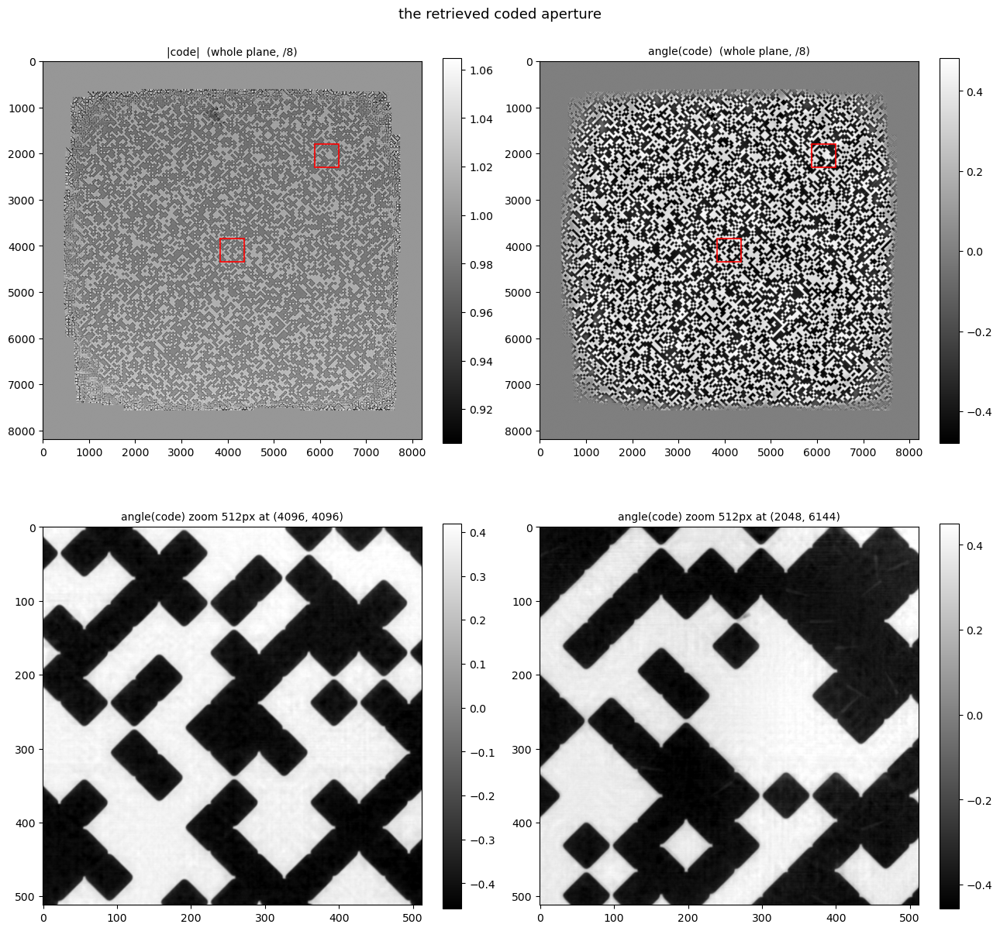

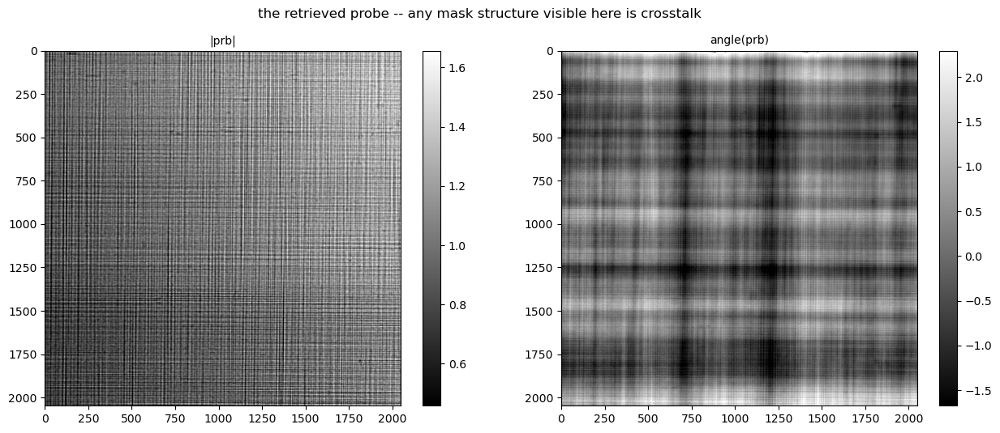

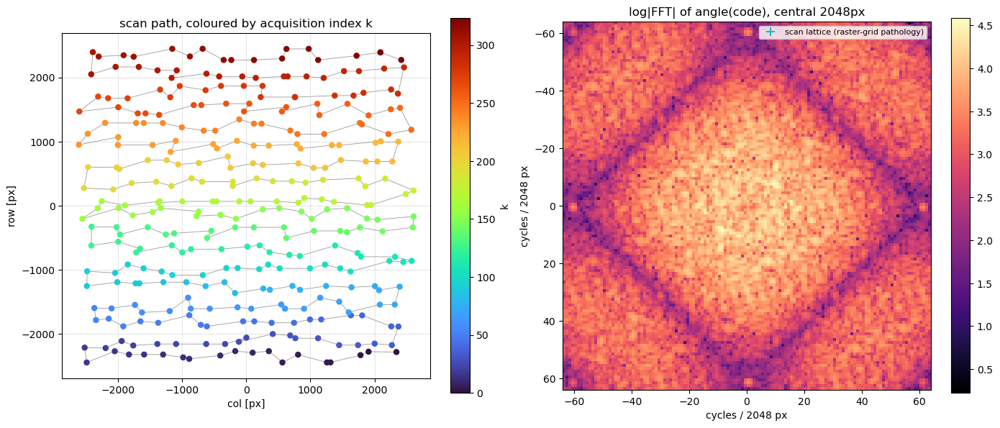


consecutive-frame pairs with <10% window overlap: 0
  0  -> the chain is serpentine, integration is sound on that count


In [8]:
# ---- load ------------------------------------------------------------------
DS = 8                                  # downsample for the 8192^2 overview
ZW = 512                                # zoom window, full resolution

cm = np.load(PATH_CODE, mmap_mode='r')
N  = cm.shape[0]
small = np.empty((N // DS, N // DS), dtype='complex64')
for i in range(0, N, 1024):             # row blocks: keeps RAM flat on a 512 MB file
    blk = np.asarray(cm[i:i + 1024])
    small[i // DS:(i + 1024) // DS] = blk.reshape(-1, DS, N // DS, DS).mean(axis=(1, 3))
prb = np.load(PATH_PRB)

# scan step, derived not assumed
step_r = np.median(np.diff(np.unique(np.round(pos[:, 0] / 10) * 10)))
step_c = np.median(np.diff(np.unique(np.round(pos[:, 1] / 10) * 10)))
print(f'code {cm.shape} {cm.dtype}   probe {prb.shape} {prb.dtype}')
print(f'|code|  min {np.abs(small).min():.3f}  max {np.abs(small).max():.3f}   '
      f'phase [{np.angle(small).min():+.3f}, {np.angle(small).max():+.3f}] rad')
print(f'scan step ~ {step_r:.0f} px (row), {step_c:.0f} px (col)  '
      f'= {step_r * vox * 1e6:.2f}, {step_c * vox * 1e6:.2f} um at the code plane')

# ---- 1. the aperture -------------------------------------------------------
off = int(0.25 * N)
_c  = lambda v: int(np.clip(v, ZW // 2, N - ZW // 2))
zc  = [(N // 2, N // 2), (_c(N // 2 - off), _c(N // 2 + off))]
fig, ax = plt.subplots(2, 2, figsize=(13, 12.5))
for a, img, t in ((ax[0, 0], np.abs(small), '|code|  (whole plane, /%d)' % DS),
                  (ax[0, 1], np.angle(small), 'angle(code)  (whole plane, /%d)' % DS)):
    lo, hi = np.percentile(img, [0.5, 99.5])
    im = a.imshow(img, cmap='gray', vmin=lo, vmax=hi, extent=(0, N, N, 0))
    a.set_title(t, fontsize=10); fig.colorbar(im, ax=a, fraction=0.046)
    for (ry, rx) in zc:
        a.add_patch(plt.Rectangle((rx - ZW // 2, ry - ZW // 2), ZW, ZW,
                                  ec='red', fc='none', lw=1.2))
for a, (ry, rx) in zip((ax[1, 0], ax[1, 1]), zc):
    z = np.angle(np.asarray(cm[ry - ZW // 2:ry + ZW // 2, rx - ZW // 2:rx + ZW // 2]))
    lo, hi = np.percentile(z, [0.5, 99.5])
    im = a.imshow(z, cmap='gray', vmin=lo, vmax=hi)
    a.set_title(f'angle(code) zoom {ZW}px at ({ry}, {rx})', fontsize=10)
    fig.colorbar(im, ax=a, fraction=0.046)
plt.suptitle('the retrieved coded aperture', fontsize=13)
plt.tight_layout(); plt.show()

# ---- 2. the probe ----------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5.4))
for a, img, t in ((ax[0], np.abs(prb), '|prb|'), (ax[1], np.angle(prb), 'angle(prb)')):
    lo, hi = np.percentile(img, [0.5, 99.5])
    im = a.imshow(img, cmap='gray', vmin=lo, vmax=hi)
    a.set_title(t, fontsize=10); fig.colorbar(im, ax=a, fraction=0.046)
plt.suptitle('the retrieved probe -- any mask structure visible here is crosstalk', fontsize=12)
plt.tight_layout(); plt.show()

# ---- 3. scan path and spectrum --------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

s = ax[0].scatter(pos[:, 1], pos[:, 0], c=np.arange(len(pos)), cmap='turbo', s=26, zorder=3)
ax[0].plot(pos[:, 1], pos[:, 0], '-', color='0.6', lw=0.6, zorder=2)
d = np.hypot(*np.diff(pos, axis=0).T)                      # consecutive-frame distance
bad = np.where(d > n * 0.9)[0]                             # pairs with ~no overlap
if len(bad):
    ax[0].plot(pos[np.r_[bad, bad + 1], 1], pos[np.r_[bad, bad + 1], 0],
               'rx', ms=11, mew=2, zorder=4,
               label=f'{len(bad)} consecutive pairs with <10% overlap')
    ax[0].legend(fontsize=8)
ax[0].set(xlabel='col [px]', ylabel='row [px]',
          title='scan path, coloured by acquisition index k')
ax[0].set_aspect('equal'); ax[0].grid(alpha=0.3)
fig.colorbar(s, ax=ax[0], fraction=0.046, label='k')

M = min(2048, N)
ph = np.angle(np.asarray(cm[N // 2 - M // 2:N // 2 + M // 2, N // 2 - M // 2:N // 2 + M // 2]))
w1 = np.hanning(M)
F = np.fft.fftshift(np.abs(np.fft.fft2((ph - ph.mean()) * np.outer(w1, w1))))
B = 64
Fc = np.log10(F[M // 2 - B:M // 2 + B, M // 2 - B:M // 2 + B] + 1e-6)
im = ax[1].imshow(Fc, cmap='magma', extent=(-B, B, B, -B))
for k_ in range(1, 6):                                    # scan lattice
    for sgn in (-1, 1):
        ax[1].plot(sgn * k_ * M / step_c, 0, 'c+', ms=9, mew=1.4)
        ax[1].plot(0, sgn * k_ * M / step_r, 'c+', ms=9, mew=1.4)
ax[1].plot([], [], 'c+', ms=9, mew=1.4, label='scan lattice (raster-grid pathology)')
ax[1].set(xlim=(-B, B), ylim=(B, -B), xlabel='cycles / %d px' % M, ylabel='cycles / %d px' % M,
          title=f'log|FFT| of angle(code), central {M}px')
ax[1].legend(fontsize=8, loc='upper right')
fig.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

print(f'\nconsecutive-frame pairs with <10% window overlap: {len(bad)}'
      + (f'  at k = {bad.tolist()}' if 0 < len(bad) <= 25 else ''))
print('  0  -> the chain is serpentine, integration is sound on that count'
      if len(bad) == 0 else
      '  >0 -> step0b cross-correlated non-overlapping frames and integrated the result;'
      '\n        every position after the first break inherits it')


In [ ]:
k = 171
meas, mod, dif = store[k]
v = np.percentile(np.abs(dif[c_]), 99)
plt.imsave('/tmp/dif.png',   dif,  cmap='seismic', vmin=-v, vmax=v)
plt.imsave('/tmp/ratio.png', meas / np.maximum(mod, 1e-3), cmap='gray', vmin=0.85, vmax=1.15)
for (ry, rx) in ((1024, 1024), (300, 1024), (1024, 300)):
    plt.imsave(f'./dif_{ry}_{rx}.png', dif[ry-256:ry+256, rx-256:rx+256],
               cmap='seismic', vmin=-v, vmax=v)
print('saved')


saved


: 

: 